### Top Rows

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, HTML

def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html()}
    </div>
    """))
    
file_path = "results-filtered.xlsx"

# df = pd.read_excel(file_path, sheet_name="kPEX-bad-heur")
# versions="v0 v1 v2 v3".split()

df = pd.read_excel(file_path, sheet_name="kPEX")
versions="v0 v1 v2 v3 v4".split()

# df = pd.read_excel(file_path, sheet_name="UMKP+AltRB")
# versions="v0 v1 v2 v3".split()

branchings="S".split()

for v in versions: 
    df[f"{v}-prep"] = (df[f"{v}-S-bnb"] == "prep")
    cols = [f"{v}-{b}-ctcp" for b in branchings]
    df[f"{v}-ctcp"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )
    cols = [f"{v}-{b}-heur" for b in branchings]
    df[f"{v}-heur"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )    

    
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)

df = clean_dataframe(df)

for v in versions: 
    df[f"{v}-init"] = df[f"{v}-heur"]+df[f"{v}-ctcp"]
    df[f"{v}-prep"] = df[f"{v}-prep"].replace(False, "")
    
df.head()
pd.set_option('display.float_format', '{:.1f}'.format)
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)


/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_37192/2280276734.py:48: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_37192/2280276734.py:48: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_37192/2280276734.py:48: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To reta

,v4-S-heur,dataset,k,v0-S-total,v1-S-total


np.int64(0)

### Varying Ratio Threshold

In [29]:
def compare_speedups(df, col_a, col_b,
                     thresholds=[1.2, 2, 4, 6, 8, 10],
                     min_time_threshold=1.0,
                     max_len=50,
                     sort_by="speedup"):  # <-- single control point
    
    import matplotlib.pyplot as plt

    # =========================
    # Setup
    # =========================
    va = col_a.split("-")[0]
    vb = col_b.split("-")[0]

    # =========================
    # Handle zeros
    # =========================
    df = df.replace(0, 0.01)

    # =========================
    # Filter
    # =========================
    df_filtered = df[
        (df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)
    ].copy()

    # =========================
    # Compute speedups
    # =========================
    df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
    df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

    # =========================
    # Sorting helper (ONLY PLACE TO CHANGE LOGIC)
    # =========================
    def sort_df(df_in, side):
        if sort_by == "speedup":
            key = "speedup_a" if side == "A" else "speedup_b"
        elif sort_by == "runtime":
            key = col_a if side == "A" else col_b
        else:
            raise ValueError("sort_by must be 'speedup' or 'runtime'")
        return df_in.sort_values(by=key, ascending=False)

    # =========================
    # Threshold = first threshold
    # =========================
    threshold_check = thresholds[0]

    a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
    b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

    # =========================
    # Determine weaker & stronger
    # =========================
    if len(a_wins) < len(b_wins):
        weaker, stronger = "A", "B"
    elif len(b_wins) < len(a_wins):
        weaker, stronger = "B", "A"
    else:
        weaker = stronger = "Tie"

    # =========================
    # Formatting function
    # =========================
    def format_df(df_in, side):
        if side == "A":
            speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}")
        else:
            speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}")

        return df_in.assign(
            dataset=df_in["dataset"].apply(
                lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
            ),
            speedup=speedup_series
        )[[
            "dataset", "k",
            col_a, col_b, 
            # "v4-S-total",
            "speedup"
            # f"{va}-ctcp", f"{vb}-ctcp",
            # f"{va}-heur", f"{vb}-heur",
            # f"{va}-init", f"{vb}-init",
            # f"{va}-S-bnb", f"{vb}-S-bnb",
            # f"{va}-S-total", f"{vb}-S-total"
        ]]

    # =========================
    # Print summary
    # =========================
    print(f"\n=== Threshold {threshold_check} Analysis ===")
    print(f"{col_a} wins: {len(a_wins)}")
    print(f"{col_b} wins: {len(b_wins)}")
    print(f"Sorting by: {sort_by}")

    # =========================
    # Display results
    # =========================
    if weaker == "Tie":
        print("Both sides have equal wins.")

        print("\n--- Side A (>= threshold) ---")
        display_scroll(format_df(sort_df(a_wins, "A"), "A"))

        print("\n--- Side B (>= threshold) ---")
        display_scroll(format_df(sort_df(b_wins, "B"), "B"))

    else:
        if weaker == "A":
            weaker_df = sort_df(a_wins, "A")
            stronger_df = sort_df(b_wins, "B")
            weaker_name, stronger_name = col_a, col_b

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "A"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "B"))

        else:
            weaker_df = sort_df(b_wins, "B")
            stronger_df = sort_df(a_wins, "A")
            weaker_name, stronger_name = col_b, col_a

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "B"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "A"))

    # =========================
    # Sensitivity analysis
    # =========================
    a_counts = [(df_filtered["speedup_a"] >= t).sum() for t in thresholds]
    b_counts = [(df_filtered["speedup_b"] >= t).sum() for t in thresholds]

    # =========================
    # Plot
    # =========================
    x = range(len(thresholds))
    width = 0.35

    plt.figure()

    bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
    bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

    def add_labels(bars):
        for bar in bars:
            height = bar.get_height()
            plt.text(
                bar.get_x() + bar.get_width()/2,
                height,
                f"{int(height)}",
                ha='center',
                va='bottom'
            )

    add_labels(bars_a)
    add_labels(bars_b)

    plt.xticks(x, thresholds)
    plt.xlabel("Speedup Threshold (x)")
    plt.ylabel("Number of rows")
    plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")
    plt.legend()
    plt.show()

v0: logs/UMKPEX_edit-zhwiki_10_S-Br_kPEX-Heur_kPEX_AltRB_CTCP.log
v2: logs/UMKPEX_edit-zhwiki_10_S-Br_EGO-Heur_kPEX_CTCP.log


=== Threshold 1.2 Analysis ===
v0-S-total wins: 1176
v1-S-total wins: 118
Sorting by: speedup

--- Weaker side: v1-S-total ---


,dataset,k,v0-S-total,v1-S-total,speedup
3071,ship_003,8,1.3,0.2,7.00
2533,pdb1HYS,4,1.1,0.5,2.28
1380,friendster,20,7.5,3.5,2.16
1294,Fault_639,2,1.0,0.5,2.13
2654,pkustk13,3,1.9,0.9,2.08
3520,soc-pokec,20,3.4,1.7,2.00
2538,pdb1HYS,10,1.0,0.5,1.95
4265,wikipedia_link_ja,15,1.5,0.8,1.95
3530,soc-pokec-relationships,20,3.3,1.7,1.93
2467,orkut-links,3,1.2,0.6,1.92



--- Stronger side: v0-S-total ---


,dataset,k,v0-S-total,v1-S-total,speedup
503,bibd_22_8,3,0.9,58.0,64.91
502,bibd_22_8,2,1.1,62.4,56.78
492,bibd_20_10,2,1.1,61.7,53.74
496,bibd_20_10,7,1.2,56.3,45.40
493,bibd_20_10,3,1.2,51.5,44.46
494,bibd_20_10,5,1.2,47.7,41.00
504,bibd_22_8,6,1.1,42.0,38.21
495,bibd_20_10,6,1.4,54.1,37.41
498,bibd_20_10,9,1.2,43.0,36.15
497,bibd_20_10,8,1.5,51.9,35.77


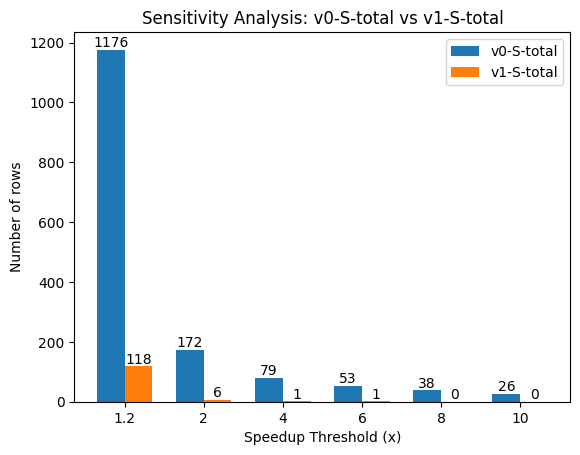

In [34]:
compare_speedups(df, "v0-S-total", "v1-S-total")